<a href="https://colab.research.google.com/github/sanya-6976/loan-approval-ml-project/blob/main/loan_approval_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv"
df = pd.read_csv(url)

print("shape:" , df.shape)
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n--- Target Distribution (%) ---")
print(df['Loan_Status'].value_counts(normalize=True)*100)



shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



--- Missing Values ---
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

--- Target Distribution (%) ---
Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


NOTE :- LOAN_ID IS THE COLUMN
TO BE DROPPED.


# **EDA & Data Leakage-Free Preprocessing**

     Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0      Male      No          0      Graduate            No             5849   
1      Male     Yes          1      Graduate            No             4583   
2      Male     Yes          0      Graduate           Yes             3000   
3      Male     Yes          0  Not Graduate            No             2583   
4      Male      No          0      Graduate            No             6000   
..      ...     ...        ...           ...           ...              ...   
609  Female      No          0      Graduate            No             2900   
610    Male     Yes         3+      Graduate            No             4106   
611    Male     Yes          1      Graduate            No             8072   
612    Male     Yes          2      Graduate            No             7583   
613  Female      No          0      Graduate           Yes             4583   

     CoapplicantIncome  LoanAmount  Loan_Amount_Ter

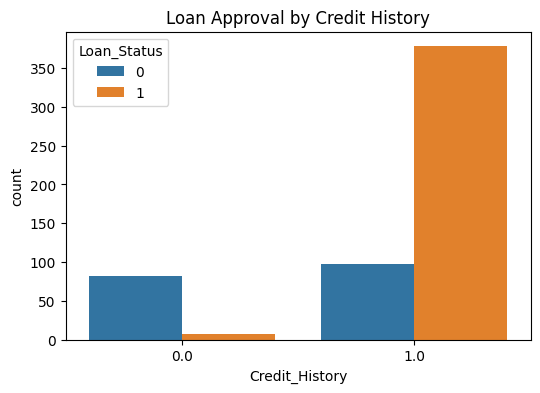

     Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
154    Male      No          0      Graduate            No             3254   
239    Male     Yes          1      Graduate            No             3315   
448    Male     Yes          2      Graduate            No             3340   
471    Male     Yes          1  Not Graduate            No             2653   
273    Male     Yes          0      Graduate            No             2620   
..      ...     ...        ...           ...           ...              ...   
222    Male      No          0      Graduate            No             2971   
349    Male     Yes          0      Graduate            No             2625   
26     Male     Yes          0      Graduate            No             2799   
96   Female     Yes          0      Graduate            No             2484   
354  Female     Yes          0      Graduate            No             2423   

     CoapplicantIncome  LoanAmount  Loan_Amount_Ter

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# DROP LOAN_ID COLUMN AND ENCODE LOAN STATUS AS (Y -> 1, N -> 0)
df_clean = df.drop(columns=["Loan_ID"]).copy()
df_clean["Loan_Status"] = df_clean["Loan_Status"].map({'Y': 1, 'N': 0})
print(df_clean)

plt.figure(figsize=(6 , 4))
sns.countplot(data = df_clean , x ="Credit_History" , hue = 'Loan_Status')
plt.title('Loan Approval by Credit History')
plt.show()

X = df_clean.drop(columns=["Loan_Status"])
y = df_clean['Loan_Status']

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state=42 , stratify=y)
print(X_train)
print(X_test)
print(y_train)
print(y_test)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

# **Preprocessing Pipeline & Baseline Decision Tree**

**"We chose Decision Tree as our baseline because loan approval follows non-linear, rule-based thresholds on tabular data without needing feature scaling. Plus, an unpruned tree immediately exposes variance and overfitting on this small dataset, giving us a clear benchmark to justify moving to ensembles like Random Forest and Gradient Boosting.**

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Corrected column names (removed extra 'o' in Applicant and Coapplicant)
num_col = ['ApplicantIncome' , 'CoapplicantIncome' , 'LoanAmount' , 'Loan_Amount_Term' , 'Credit_History']
cat_col =['Gender' , 'Married' , 'Education' , 'Self_Employed' ,'Property_Area']


#preprocessing pipelines
num_transformer = SimpleImputer(strategy = 'median')
cat_transformer = Pipeline(steps = [
    ('imputer' , SimpleImputer(strategy='most_frequent')) ,
('onehot' , OneHotEncoder(handle_unknown ='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num' , num_transformer , num_col) ,
    ('cat' , cat_transformer , cat_col)
])

dt_pipeline = Pipeline(steps=[
    ('preprocessor' , preprocessor) ,
    ('classifier' , DecisionTreeClassifier(random_state = 42))
])
dt_pipeline.fit(X_train, y_train)


train_pred = dt_pipeline.predict(X_train)
test_pred = dt_pipeline.predict(X_test)
test_proba = dt_pipeline.predict_proba(X_test)[:, 1]

print(f"Train Accuracy : {accuracy_score(y_train, train_pred):.4f}")
print(f"Test Accuracy  : {accuracy_score(y_test, test_pred):.4f}")
print(f"Test F1-Score  : {f1_score(y_test, test_pred):.4f}")
print(f"Test ROC-AUC   : {roc_auc_score(y_test, test_proba):.4f}")

Train Accuracy : 1.0000
Test Accuracy  : 0.7154
Test F1-Score  : 0.7879
Test ROC-AUC   : 0.6850


# **Pruned Tree vs Ensemble Models (Random Forest & Gradient Boosting)**

# **Problem:** Step 3 mein humara unpruned Decision Tree overfit kar raha tha (~100% Train vs ~71.5% Test accuracy) kyunki ek akela tree high-variance hota hai aur training data ki noise memorize kar leta hai.

# **Solution — **

# **Pre-Pruning (max_depth=3):** Tree ki growth ko limit karna taaki wo sirf top 3 sabse important rules (Credit_History, etc.) seekhe aur noise par split na kare.

# **Random Forest (Bagging):** 100 alag-alag trees ko random data subsets (bootstrap samples) aur random feature subsets par parallel train karke unka majority vote lena. Isse variance kam hota hai without increasing bias.

# **Gradient Boosting (Boosting):** Trees ko sequentially train karna jahan har naya tree pichle trees ki galtiyon (residuals/gradients) ko sudharta hai. Isse bias aur variance dono kam hote hain.

In [30]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Pruned decision tree of max depth 3": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipe.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, pipe.predict(X_train))
    test_pred = pipe.predict(X_test)
    test_proba = pipe.predict_proba(X_test)[:, 1]

    print(f"--- {name} ---")
    print(f"Train Acc: {train_acc:.4f} | Test Acc: {accuracy_score(y_test, test_pred):.4f} | "
          f"F1: {f1_score(y_test, test_pred):.4f} | ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}\n")

--- Pruned decision tree of max depth 3 ---
Train Acc: 0.8086 | Test Acc: 0.8455 | F1: 0.8984 | ROC-AUC: 0.7375

--- Random Forest ---
Train Acc: 0.8106 | Test Acc: 0.8537 | F1: 0.9032 | ROC-AUC: 0.8307

--- Gradient Boosting ---
Train Acc: 0.8411 | Test Acc: 0.8211 | F1: 0.8804 | ROC-AUC: 0.7862



# **Domain Feature Engineering + Cross-Validation + Confusion Matrix**

5-Fold CV ROC-AUC: 0.7821 (+/- 0.0887)
Test Accuracy : 0.8618
Test F1-Score : 0.9071
Test ROC-AUC  : 0.8715


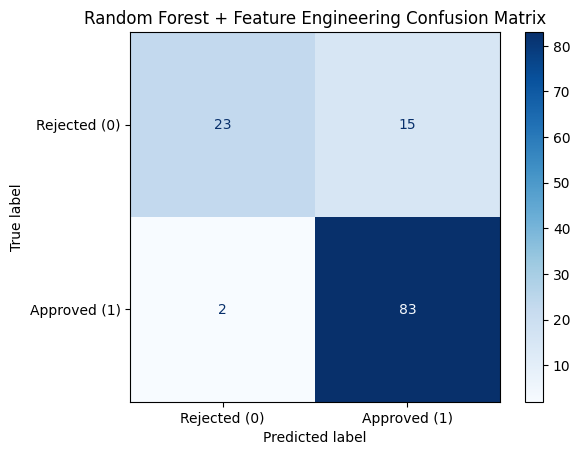

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay

def add_domain_features(data):
  df_feat = data.copy() # Corrected to use passed data instead of global df
  df_feat['TotalIncome'] = df_feat['ApplicantIncome'] + df_feat['CoapplicantIncome'] # Fixed typos

  df_feat['LoanAmount_Log'] = np.log(df_feat['LoanAmount'])
  df_feat['TotalIncome_Log'] = np.log(df_feat['TotalIncome'])

  df_feat['Loan_to_Income'] = df_feat['LoanAmount'] / (df_feat['TotalIncome'] + 1)
  return df_feat

X_train_fe = add_domain_features(X_train)
X_test_fe = add_domain_features(X_test)

# Define the feature columns specifically
num_cols_fe = num_col + ['TotalIncome', 'LoanAmount_Log', 'TotalIncome_Log', 'Loan_to_Income']
cat_cols = cat_col

preprocessor_fe = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), num_cols_fe),
    ('cat', cat_transformer, cat_cols)
])

rf_fe_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor_fe),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

cv = StratifiedKFold(n_splits=5 , shuffle = True , random_state = 42)
cv_roc = cross_val_score(rf_fe_pipe, X_train_fe, y_train, cv=cv, scoring='roc_auc')
print(f"5-Fold CV ROC-AUC: {cv_roc.mean():.4f} (+/- {cv_roc.std():.4f})")

rf_fe_pipe.fit(X_train_fe, y_train)
y_pred_fe = rf_fe_pipe.predict(X_test_fe)
y_proba_fe = rf_fe_pipe.predict_proba(X_test_fe)[:, 1]

print(f"Test Accuracy : {accuracy_score(y_test, y_pred_fe):.4f}")
print(f"Test F1-Score : {f1_score(y_test, y_pred_fe):.4f}")
print(f"Test ROC-AUC  : {roc_auc_score(y_test, y_proba_fe):.4f}")

# 4. Plot Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_fe, display_labels=['Rejected (0)', 'Approved (1)'], cmap='Blues')
plt.title("Random Forest + Feature Engineering Confusion Matrix")
plt.show()